### COCA-COLA VERSUS PEPSI ANALYSIS

### 🥤 Global Market & Equity Comparative Analytics
- This project evaluates two global beverage giants across two decades of historical market price performance, daily trading volume, and dividend growth strategies.

### Project Objectives
1. **Equity Performance:** 
- Compare long-term close price dynamics, growth trajectories, and volatility between **The Coca-Cola Company (KO)** and **PepsiCo, Inc. (PEP)**.
2. **Trading Activity:** 
- Analyze trading volume trends to evaluate institutional market liquidity.
3. **Dividend Yield & Growth:**
-  Evaluate historic dividend payouts and investor yield strategies for both corporations.

In [8]:
# Import core data manipulation and visualization packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
# Load Datasets
ko_price = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_price.csv")
pep_price = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_price.csv")
ko_div = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_dividend.csv")
pep_div = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_dividend.csv")
ko_split = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_split.csv")
pep_split = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_split.csv")


In [10]:
# Set visual style theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

In [11]:
# Convert Date columns to datetime format
ko_price['Date'] = pd.to_datetime(ko_price['Date'])
pep_price['Date'] = pd.to_datetime(pep_price['Date'])

In [12]:
ko_price

,Date,Open Price,High Price,Low Price,Close Price,Volume
0,1999-11-01,58.25,59.380,57.880,59.00,4212600.0
1,1999-11-02,58.63,58.940,57.310,57.75,3226800.0
2,1999-11-03,57.19,57.750,56.060,56.88,3958700.0
3,1999-11-04,57.50,57.500,56.060,56.69,3768500.0
4,1999-11-05,57.94,58.440,57.630,58.13,4104800.0
...,...,...,...,...,...,...
6287,2024-10-28,66.96,67.395,66.600,66.67,10761416.0
6288,2024-10-29,66.29,66.340,65.520,65.56,16525917.0
6289,2024-10-30,65.51,66.535,65.320,65.92,14177766.0
6290,2024-10-31,65.81,65.990,65.255,65.31,13383717.0


In [13]:
ko_div

,Date,Dividend
0,1962-03-13 00:00:00-05:00,0.001563
1,1962-06-11 00:00:00-04:00,0.001563
2,1962-09-11 00:00:00-04:00,0.001563
3,1962-11-28 00:00:00-05:00,0.001563
4,1963-03-11 00:00:00-05:00,0.001758
...,...,...
246,2023-09-14 00:00:00-04:00,0.460000
247,2023-11-30 00:00:00-05:00,0.460000
248,2024-03-14 00:00:00-04:00,0.485000
249,2024-06-14 00:00:00-04:00,0.485000


In [14]:
ko_split

,Date,Stock Splits
0,1965-02-19 00:00:00-05:00,2:01
1,1968-06-03 00:00:00-04:00,2:01
2,1977-06-01 00:00:00-04:00,2:01
3,1986-07-01 00:00:00-04:00,3:01
4,1990-05-14 00:00:00-04:00,2:01
5,1992-05-12 00:00:00-04:00,2:01
6,1996-05-13 00:00:00-04:00,2:01
7,2012-08-13 00:00:00-04:00,2:01


In [20]:
pep_split

,Date,Stock Splits
0,1977-05-31 00:00:00-04:00,3:01
1,1986-05-29 00:00:00-04:00,3:01
2,1990-09-05 00:00:00-04:00,3:01
3,1996-05-29 00:00:00-04:00,2:01


**Key Metric Summary (KPI Dashboard)**

In [15]:
# Compute core and advanced performance metrics
def compute_advanced_metrics(df):
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values('Date').reset_index(drop=True)
    
    start_price = df['Close Price'].iloc[0]
    end_price = df['Close Price'].iloc[-1]
    years = (df['Date'].iloc[-1] - df['Date'].iloc[0]).days / 365.25
    cagr = ((end_price / start_price) ** (1 / years) - 1) * 100
    
    df['Daily_Return'] = df['Close Price'].pct_change()
    ann_vol = df['Daily_Return'].std() * (252 ** 0.5) * 100
    
    rolling_max = df['Close Price'].cummax()
    drawdown = (df['Close Price'] - rolling_max) / rolling_max
    max_dd = drawdown.min() * 100
    
    return cagr, ann_vol, max_dd

ko_cagr, ko_vol, ko_max_dd = compute_advanced_metrics(ko_price)
pep_cagr, pep_vol, pep_max_dd = compute_advanced_metrics(pep_price)

ko_latest_price = ko_price['Close Price'].iloc[-1]
pep_latest_price = pep_price['Close Price'].iloc[-1]
ko_avg_vol = ko_price['Volume'].mean() / 1e6
pep_avg_vol = pep_price['Volume'].mean() / 1e6
ko_max_price = ko_price['Close Price'].max()
pep_max_price = pep_price['Close Price'].max()

# Display summary dataframe with 3 additional performance metrics
kpi_df = pd.DataFrame({
    'Metric': [
        'Latest Close Price ($)', 
        'All-Time High Close ($)', 
        'Average Daily Volume (M shares)', 
        'Compound Annual Growth Rate (CAGR)', 
        'Annualized Volatility (%)', 
        'Maximum Drawdown (%)'
    ],
    'Coca-Cola (KO)': [
        f"${ko_latest_price:.2f}", 
        f"${ko_max_price:.2f}", 
        f"{ko_avg_vol:.2f}M", 
        f"{ko_cagr:.2f}%", 
        f"{ko_vol:.2f}%", 
        f"{ko_max_dd:.2f}%"
    ],
    'PepsiCo (PEP)': [
        f"${pep_latest_price:.2f}", 
        f"${pep_max_price:.2f}", 
        f"{pep_avg_vol:.2f}M", 
        f"{pep_cagr:.2f}%", 
        f"{pep_vol:.2f}%", 
        f"{pep_max_dd:.2f}%"
    ]
})

print("=== EXECUTIVE KPI SUMMARY DASHBOARD (ENHANCED) ===")
display(kpi_df)

=== EXECUTIVE KPI SUMMARY DASHBOARD (ENHANCED) ===


,Metric,Coca-Cola (KO),PepsiCo (PEP)
0,Latest Close Price ($),$65.01,$165.59
1,All-Time High Close ($),$81.12,$196.12
2,Average Daily Volume (M shares),10.80M,5.20M
3,Compound Annual Growth Rate (CAGR),0.39%,6.59%
4,Annualized Volatility (%),23.04%,20.07%
5,Maximum Drawdown (%),-55.66%,-42.43%


**Visualization 1 — Long-Term Stock Price Comparison**

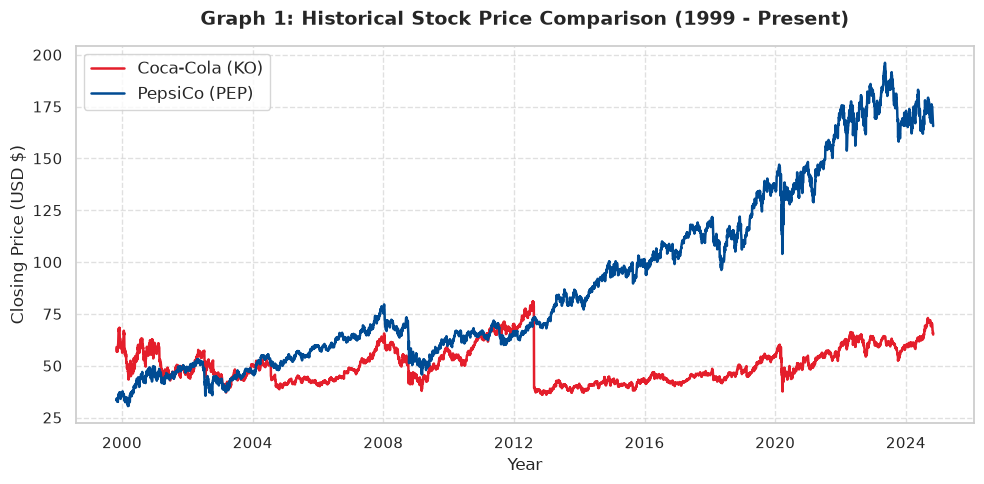

In [16]:
# Graph 1: Comparative Historical Closing Prices
plt.figure(figsize=(10, 5))

plt.plot(ko_price['Date'], ko_price['Close Price'], label='Coca-Cola (KO)', color='#E41E2B', linewidth=1.8)
plt.plot(pep_price['Date'], pep_price['Close Price'], label='PepsiCo (PEP)', color='#004B93', linewidth=1.8)

plt.title('Graph 1: Historical Stock Price Comparison (1999 - Present)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Closing Price (USD $)', fontsize=12)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Visualization 2 — Average Daily Trading Volume Distribution**

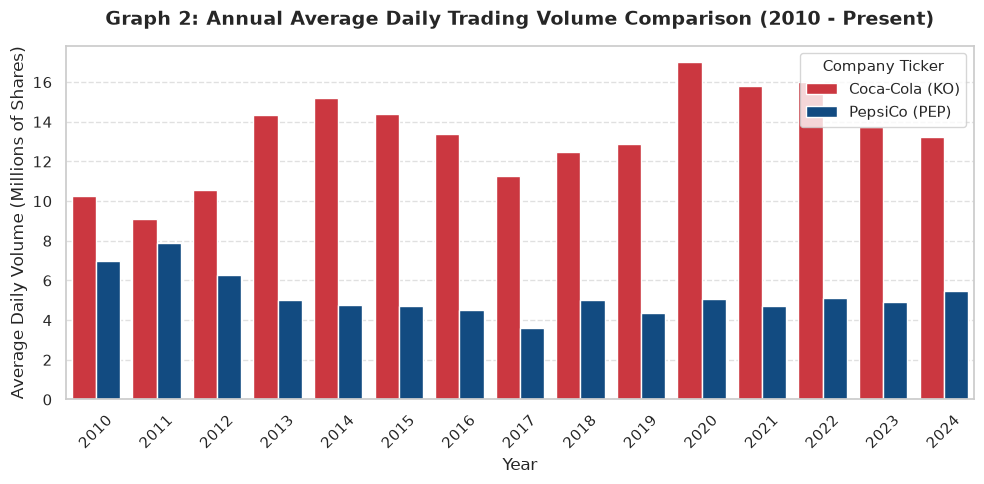

In [17]:
# Graph 2: Comprehensive Grouped Bar Chart of Annual Average Daily Trading Volume
ko_price['Year'] = ko_price['Date'].dt.year
pep_price['Year'] = pep_price['Date'].dt.year

# Aggregate annual mean volume
ko_annual = ko_price.groupby('Year')['Volume'].mean().reset_index()
ko_annual['Ticker'] = 'Coca-Cola (KO)'
pep_annual = pep_price.groupby('Year')['Volume'].mean().reset_index()
pep_annual['Ticker'] = 'PepsiCo (PEP)'

combined_annual = pd.concat([ko_annual, pep_annual], ignore_index=True)
combined_annual['Volume_M'] = combined_annual['Volume'] / 1e6

# Filter for the modern era (2010 onwards) for clarity
recent_annual = combined_annual[combined_annual['Year'] >= 2010]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=recent_annual, 
    x='Year', 
    y='Volume_M', 
    hue='Ticker', 
    palette=['#E41E2B', '#004B93']
)

plt.title('Graph 2: Annual Average Daily Trading Volume Comparison (2010 - Present)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Daily Volume (Millions of Shares)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Company Ticker', fontsize=11, title_fontsize=11, loc='upper right')
plt.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Visualization 3 — Historical Dividend Yield Trends**

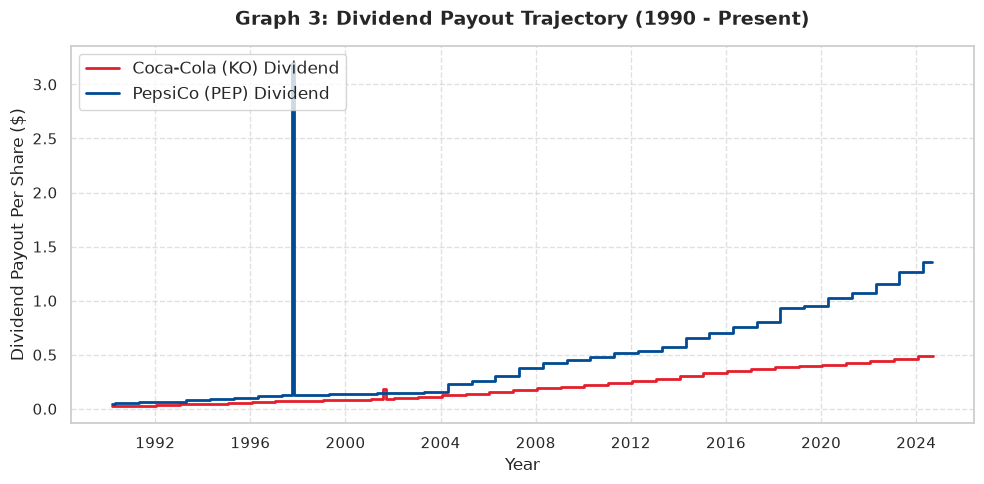

In [18]:
# Graph 3: Historic Dividend Growth Trajectory
ko_div['Date'] = pd.to_datetime(ko_div['Date'], utc=True).dt.tz_localize(None)
pep_div['Date'] = pd.to_datetime(pep_div['Date'], utc=True).dt.tz_localize(None)

# Filter for modern era dividends (1990 onwards)
ko_div_modern = ko_div[ko_div['Date'] >= '1990-01-01']
pep_div_modern = pep_div[pep_div['Date'] >= '1990-01-01']

plt.figure(figsize=(10, 5))

plt.step(ko_div_modern['Date'], ko_div_modern['Dividend'], where='mid', label='Coca-Cola (KO) Dividend', color='#E41E2B', linewidth=2)
plt.step(pep_div_modern['Date'], pep_div_modern['Dividend'], where='mid', label='PepsiCo (PEP) Dividend', color='#004B93', linewidth=2)

plt.title('Graph 3: Dividend Payout Trajectory (1990 - Present)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Dividend Payout Per Share ($)', fontsize=12)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Visualization 4 — Cumulative Percentage Growth Index**
- Directly answers which equity compounded an investor's capital better over the long run by setting a fair starting point ($100) for both.

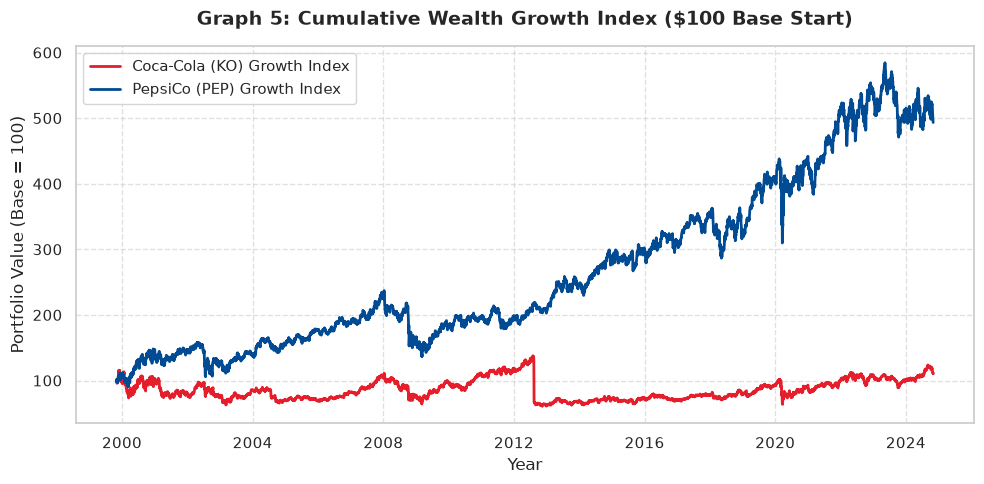

In [19]:
# Graph 5: Cumulative Return Growth Index (Base 100)
ko_merged = ko_price.dropna(subset=['Close Price']).copy()
pep_merged = pep_price.dropna(subset=['Close Price']).copy()

# Normalize to 100 at the start date
ko_merged['Cumulative_Growth'] = (ko_merged['Close Price'] / ko_merged['Close Price'].iloc[0]) * 100
pep_merged['Cumulative_Growth'] = (pep_merged['Close Price'] / pep_merged['Close Price'].iloc[0]) * 100

plt.figure(figsize=(10, 5))

plt.plot(ko_merged['Date'], ko_merged['Cumulative_Growth'], label='Coca-Cola (KO) Growth Index', color='#E41E2B', linewidth=2)
plt.plot(pep_merged['Date'], pep_merged['Cumulative_Growth'], label='PepsiCo (PEP) Growth Index', color='#004B93', linewidth=2)

plt.title('Graph 5: Cumulative Wealth Growth Index ($100 Base Start)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Portfolio Value (Base = 100)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 📌 Executive Takeaways
* **Price Dynamics:**
-  PepsiCo (`PEP`) exhibits higher nominal stock price growth over the multi-decade window, while Coca-Cola (`KO`) maintains lower per-share prices but high consistency.
* **Liquidity & Volume:**
-  Coca-Cola consistently averages higher daily trading volumes (~10.8M shares/day) compared to PepsiCo (~5.2M shares/day), reflecting distinct institutional retail participation profiles.
* **Dividend Growth:** 
- Both corporations demonstrate consistent step-wise dividend growth, classifying them as key dividend aristocrats.